## Download DEM

This is an example workflow for easily obtaining a digital elevation model (DEM) topograhic data from OpenTopography.
To obtain a DEM from OpenTopography, a user needs to supply the lattitude and longitude of the bounding box of the region of interest. 
OpenTopography also needs the desired DEM format (ASCII or GeoTIFF) and the source database to pull from (see list above). 

The global datasets available are listed below. Please enter one below.
  -  SRTMGL3 (SRTM GL3 90m)
  -  SRTMGL1 (SRTM GL1 30m)
  -  SRTMGL1_E (SRTM GL1 Ellipsoidal 30m)
  -  AW3D30 (ALOS World 3D 30m)
  -  AW3D30_E (ALOS World 3D Ellipsoidal, 30m)
  -  SRTM15Plus (Global Bathymetry SRTM15+ V2.1)
  -  NASADEM (NASADEM Global DEM)
  -  COP30 (Copernicus Global DSM 30m)
  -  COP90 (Copernicus Global DSM 90m)
  -  EU_DTM (DTM 30m)

The script will save the resulting DEM with a standardize file name in the user's home directory. 

### Import needed libraries

In [1]:
#Don't change anything, just run the code
import urllib.request
import utm
import sys
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import rasterio as rio
import xarray as xr

import openpyxl

In [2]:
#Don't change anything, just run the code
sys.path.insert(0,"/home/jovyan/shared/Libraries")
import victor

### Setting input parameters

In the following cell we use the lat/lon of a target volcano's summit, obtained from the Global Volcano Project database from the volcano'es name, to set the bounding box.


In [3]:
#Choose a volcano and DEM options

#Type in the name of the target volcano. The name must match the GVP name
volcano = victor.search_volcano('Pinatubo') # Get volcano information from the GVP database

center_lat = volcano[1][0]  # Get volcano latitude
center_lon = volcano[2][0]  # Get volcano longitude

# Set the extent of the region of interest, in meters in each direction from the summit
eastwest_extent = 10000
northsouth_extent = 10000

# Set bounding box in lat/lon
utms = utm.from_latlon(center_lat, center_lon)
[north_lat, east_lon] = utm.to_latlon(utms[0]+eastwest_extent, utms[1]+northsouth_extent, utms[2], utms[3])
[south_lat, west_lon] = utm.to_latlon(utms[0]-eastwest_extent, utms[1]-northsouth_extent, utms[2], utms[3])

# Select a DEM format: Input "ascii" for ASCII format (.asc) and "tiff" for geotiff format
outputFormat = "tiff"

# Enter the name of the output file (without extension)
name = "Pinatubo"

dataset = "SRTMGL1"

print(center_lat, center_lon) 

46.2 -122.18


### Obtain DEM 
This cells obtains the DEM from OpenTopograhy using the input options. It will print out the resulting file name. 

In [4]:
#Don't change anything, just run the code
dem = victor.download_dem(north_lat, south_lat, east_lon, west_lon, outputFormat, dataset)
print (dem)

DEM downloaded as DEM_46N_121W_SRTMGL1_17062026.geotiff
DEM_46N_121W_SRTMGL1_17062026.geotiff


### DEM Visualization 
To make sure we got what we wanted, the next cell will plot the DEM using the victor.py DEM visualization function

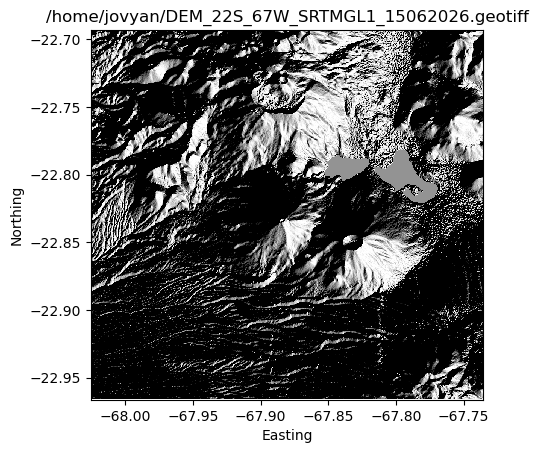

In [5]:
#Don't change anything, just run the code
victor.plot_dem('/home/jovyan/'+dem)
plt.savefig(name)